# Time-series analysis of Pandora visits (VISDA and NIRDA)

This notebook takes every VISDA (`*_VisSci_*_l2.fits`) and NIRDA (`*_InfImg_*_l2.fits`) Level 2 file in a folder, reduces each to a light curve, groups the files into visits, removes instrumental trends over each visit, and looks at the planet's transits in both detectors and in a few NIR wavelength channels. The per-file reductions follow `01_visda_reduction.ipynb` and `02_nirda_reduction.ipynb`, which explain them in detail.

A Pandora observation of a target is a series of files, roughly one per orbit (about 95 minutes), each typically 30 to 40 minutes long, taken while the target is visible. Files close together in time form a *visit*. A transit (WASP-52b: 1.8 hours) is longer than a file, so trends must be removed over whole visits, not file by file, or the transit would be fitted away.

**Steps:**

1. **Per-file reduction.** VISDA: aperture sum, centroid, background. NIRDA: spectra with bad pixels masked and filled from the trace profile, the trace's column position, background.
2. **NIRDA light curves** (white light and the wavelength channels in `CHANNELS`) built on a common wavelength grid, so that the shifting wavelength solution and the rows left out do not change them from file to file.
3. **Times** at mid-exposure, converted to BJD_TDB to match published ephemerides.
4. **Visits** are runs of files separated by less than `VISIT_GAP_HOURS`.
5. **Frame flags.** The first `SETTLE_MINUTES` of each file (pointing settle and detector ramp after a slew), frames with the target more than `MAX_OFFSET_PIXELS` from its usual position, and frames whose background is more than `BACKGROUND_SIGMA` robust standard deviations above its median in the file (scattered earthshine, typically at the end of a file).
6. **Detrending per visit.** Out of transit, the relative flux is fitted with a quadratic in time over the visit, the target's position offsets, and two exponential ramps since the start of each file; the light curve is divided by this model.
7. **Transit.** Folded light curves and a simple box depth per detector and channel.

Set `DIRECTORY` and the planet's ephemeris below. Without an ephemeris (`EPHEMERIS = None`) the notebook stops after the detrended light curves.

In [1]:
# Standard library
import warnings
from pathlib import Path

# Third-party
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.coordinates import EarthLocation
from astropy.time import Time
from scipy.ndimage import binary_dilation, median_filter

# First-party/Local
import pandorafits as pf

plt.style.use(pf.PANDORASTYLE)
warnings.simplefilter("ignore", RuntimeWarning)
pf.logger.setLevel("ERROR")

In [2]:
DIRECTORY = Path("Path", "to", "level2")

# WASP-52b. Ephemeris in BJD_TDB from Kokori et al. 2023; Rp/R* (only used
# for a reference line) from the same source.
EPHEMERIS = dict(t0=2456784.057988, period=1.74978117, duration_hours=1.81)
RP_RS = 0.1646

VISIT_GAP_HOURS = 6
SETTLE_MINUTES = 2
MAX_OFFSET_PIXELS = 1
BACKGROUND_SIGMA = 5
OUTLIER_SIGMA = 5
BIN_MINUTES = 5
# Extra time [minutes] around the predicted transit treated as in transit,
# for ephemeris uncertainty.
TRANSIT_MARGIN_MINUTES = 10
# NIRDA wavelength channels [micron], not overlapping: 0.2 micron bins,
# split around narrow bins at the He I 1.083 micron line and the 1.4 micron
# water band, so each feature has continuum channels next to it. NIRDA's
# usable range is about 0.88-1.63 micron, so the outer bins are partly
# empty. A NIRDA resolution element is ~19 nm (16 nm in the blue to 25 nm
# in the red; R ~ 60) and a row ~3.6 nm, so the narrowest useful channel
# is one resolution element: 1.074-1.092 micron is one element centered on
# He I, and 1.36-1.40 micron about two.
CHANNELS = [
    (0.8, 1.0),
    (1.0, 1.074),
    (1.074, 1.092),  # He I
    (1.092, 1.2),
    (1.2, 1.36),
    (1.36, 1.40),  # water
    (1.40, 1.6),
    (1.6, 1.8),
]
# NIRDA extraction settings, as in 02_nirda_reduction.ipynb.
PROFILE_ROWS = 8
MIN_CAPTURED_FRACTION = 0.5
MIN_RELATIVE_SENSITIVITY = 0.05

## Per-file reductions

`TIME` is the start of each VISDA co-add, and for NIRDA (pandora-fits 0.9.0 and earlier) the start of the second read group of each integration. The middle of the exposure is about `TIME + EXPTIME / 2` for VISDA and `TIME - EXPTIME / 2` for NIRDA. Times are converted from JD (UTC) to BJD_TDB at the geocenter; Pandora's distance from it changes the light travel time by less than 0.03 s.

In [3]:
GEOCENTER = EarthLocation.from_geocentric(0, 0, 0, unit="m")
NEIGHBORS = np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]], dtype=bool)


def channel_name(low, high):
    return f"flux_{low:.3f}-{high:.3f}"


def to_bjd_tdb(time_jd, coord):
    times = Time(time_jd, format="jd", scale="utc", location=GEOCENTER)
    return (times.tdb + times.light_travel_time(coord)).jd


def reduce_visda_file(path):
    # Aperture sum, centroid and background per co-add (01 notebook).
    hdulist = pf.open(path)
    header = hdulist[0].header
    background = hdulist["BACKGROUND"].data
    cube = hdulist["SCIENCE"].data - background[:, None, None]
    target = (hdulist["APERTURE"].data & 2) == 2
    row_index, column_index = np.mgrid[: cube.shape[1], : cube.shape[2]]
    weights = np.where(target, cube, 0)
    flux = weights.sum(axis=(1, 2))
    mid_jd = hdulist["TIME"].data + hdulist["EXPTIME"].data / 2 / 86400
    return pd.DataFrame(dict(
        bjd=to_bjd_tdb(mid_jd, hdulist.coord),
        file_minutes=(mid_jd - mid_jd[0]) * 1440,
        flux=flux,
        column=(weights * column_index).sum(axis=(1, 2)) / flux
        + header["ROISTRTX"],
        row=(weights * row_index).sum(axis=(1, 2)) / flux
        + header["ROISTRTY"],
        background=background,
        file=path.name,
    ))


def reduce_nirda_file(path):
    # Masked-and-filled extraction (02 notebook). Returns a table per
    # integration, the spectra (integration x row), the wavelength of each
    # row and the rows left out (contaminated, insensitive or mostly
    # filled). Light curves are built from these below.
    hdulist = pf.open(path)
    background = hdulist["BACKGROUND"].data
    cube = hdulist["SCIENCE"].data - background[:, :, None]
    nframes, nrows, ncols = cube.shape
    aperture_bits = hdulist["APERTURE"].data
    target = (aperture_bits & 2) == 2
    contaminated = target & ((aperture_bits & 4) == 4)
    flagged = hdulist["QUALITY"].data != 0
    masked = target & binary_dilation(flagged, NEIGHBORS)
    good = target & ~masked

    # Temporal outliers in the aperture pixels.
    pixels = cube[:, target]
    running = median_filter(pixels, size=(7, 1), mode="nearest")
    residual = pixels - running
    sigma = 1.4826 * np.median(np.abs(residual), axis=0)
    cube[:, target] = np.where(np.abs(residual) > 7 * sigma, running, pixels)

    target_rows = target.any(axis=1)
    contaminated_rows = contaminated.any(axis=1)
    clean_rows = np.where(
        target_rows & ~(masked | contaminated).any(axis=1)
    )[0]
    clean_profiles = np.where(target[clean_rows], cube[:, clean_rows], 0)
    clean_profiles /= clean_profiles.sum(axis=2, keepdims=True)
    spectra = np.full((nframes, nrows), np.nan)
    captured = np.ones((nframes, nrows))
    for row in np.where(target_rows)[0]:
        if masked[row].any():
            nearest = np.argsort(np.abs(clean_rows - row))[:PROFILE_ROWS]
            profile = np.median(clean_profiles[:, nearest], axis=1)
            profile *= target[row]
            profile /= profile.sum(axis=1, keepdims=True)
            captured[:, row] = np.where(good[row], profile, 0).sum(axis=1)
        spectra[:, row] = (
            np.where(good[row], cube[:, row], 0).sum(axis=1)
            / captured[:, row]
        )

    solution = hdulist["WAVELENGTH_SOLUTION"].data
    wavelength = solution["wavelength"]
    sensitivity = solution["sensitivity"]
    use_rows = (
        target_rows
        & (np.median(captured, axis=0) >= MIN_CAPTURED_FRACTION)
        & (sensitivity > MIN_RELATIVE_SENSITIVITY * np.nanmax(sensitivity))
        & ~contaminated_rows
    )
    trace = np.where(good, cube, 0)
    column = (
        (trace * np.arange(ncols)).sum(axis=(1, 2)) / trace.sum(axis=(1, 2))
        + hdulist[0].header["ROISTRTX"]
    )
    mid_jd = hdulist["TIME"].data - hdulist["EXPTIME"].data / 2 / 86400
    table = pd.DataFrame(dict(
        bjd=to_bjd_tdb(mid_jd, hdulist.coord),
        file_minutes=(mid_jd - mid_jd[0]) * 1440,
        column=column,
        # Along the dispersion the trace position is taken from the
        # pointing (VECTORS posy).
        row=hdulist["VECTORS"].data["posy"],
        background=np.median(background, axis=1),
        file=path.name,
    ))
    return table, np.nan_to_num(spectra), wavelength, ~use_rows

In [4]:
visda_paths = sorted(DIRECTORY.glob("*_VisSci_*_l2.fits"))
nirda_paths = sorted(DIRECTORY.glob("*_InfImg_*_l2.fits"))
print(f"{len(visda_paths)} VISDA and {len(nirda_paths)} NIRDA files")

visda = pd.concat([reduce_visda_file(p) for p in visda_paths])
nirda_files = [reduce_nirda_file(p) for p in nirda_paths]
nirda = pd.concat([table for table, *_ in nirda_files])
first_header = pf.open(visda_paths[0])[0].header
target_name = first_header["TARG_ID"]
print(f"{len(visda)} VISDA co-adds and {len(nirda)} NIRDA integrations")

77 VISDA and 77 NIRDA files


17483 VISDA co-adds and 28119 NIRDA integrations


## Visits

Files separated by less than `VISIT_GAP_HOURS` belong to the same visit. Predicted transits (mid-times from the ephemeris) inside each visit are listed.

In [5]:
file_starts = (
    pd.concat([visda, nirda]).groupby("file")["bjd"].min().sort_values()
)
new_visit = np.diff(file_starts.values, prepend=-np.inf) > (
    VISIT_GAP_HOURS / 24
)
visit_of_file = pd.Series(np.cumsum(new_visit), index=file_starts.index)
for table in (visda, nirda):
    table["visit"] = table["file"].map(visit_of_file).values
    table.sort_values("bjd", inplace=True)
    table.reset_index(drop=True, inplace=True)


def nearest_transit(bjd):
    # Mid-time [BJD_TDB] of the predicted transit nearest each time.
    if EPHEMERIS is None:
        return np.full(np.shape(bjd), np.nan)
    epoch = np.round((bjd - EPHEMERIS["t0"]) / EPHEMERIS["period"])
    return EPHEMERIS["t0"] + epoch * EPHEMERIS["period"]


rows = []
for visit, files in visit_of_file.groupby(visit_of_file):
    in_visit = pd.concat([visda, nirda]).query("visit == @visit")
    start, stop = in_visit["bjd"].min(), in_visit["bjd"].max()
    mids = nearest_transit(np.array([start, stop]))
    transits = np.unique(mids[(mids >= start) & (mids <= stop)])
    rows.append(dict(
        visit=visit,
        start_utc=Time(start, format="jd", scale="tdb").utc.iso[:16],
        hours=round((stop - start) * 24, 1),
        visda_files=visda.loc[visda.visit == visit, "file"].nunique(),
        nirda_files=nirda.loc[nirda.visit == visit, "file"].nunique(),
        transits=len(transits),
    ))
pd.DataFrame(rows).set_index("visit")

,start_utc,hours,visda_files,nirda_files,transits
visit,,,,,
1,2026-08-31 17:29,0.3,1,1,0
2,2026-09-05 11:55,23.2,15,15,1
3,2026-09-09 12:36,23.2,15,15,1
4,2026-09-30 05:28,73.2,46,46,2


## NIRDA light curves on a common wavelength grid

Each NIRDA file has its own wavelength solution (the trace lands a fraction of a row higher or lower), and the rows left out (contaminated, insensitive or mostly filled) change a little between files as the pointing moves. Summing whole rows would then change a light curve's flux from file to file: by one row's flux, about 2% for a 0.2 µm channel and 50% for a 5 nm one. So the white light curve and the `CHANNELS` light curves are built on a fine common wavelength grid:

- each row is split into the grid points that fall within its wavelength range;
- a wavelength left out in *any* file of a visit is left out in *all* its files;
- a light curve sums each row's flux times the fraction of its grid points that are inside the channel and not left out;
- a light curve is left out of a visit where less than `MIN_COVERAGE` of the wavelengths it has in its best-covered visit remain (for WASP-52, the 0.8-1.0 µm channel in the September visits, where another star's trace covers 0.88-1.02 µm).

Light curves for other channels can be made by changing `CHANNELS` and rerunning from this cell; the files are not reduced again.

In [6]:
WAVELENGTH_GRID = np.arange(0.70, 1.90, 0.0005)  # micron


def grid_rows(wavelength):
    # Row containing each grid point, or -1 outside every row.
    edges = np.concatenate([
        [1.5 * wavelength[0] - 0.5 * wavelength[1]],
        (wavelength[1:] + wavelength[:-1]) / 2,
        [1.5 * wavelength[-1] - 0.5 * wavelength[-2]],
    ])
    low = np.minimum(edges[:-1], edges[1:])
    high = np.maximum(edges[:-1], edges[1:])
    order = np.argsort(low)
    position = np.searchsorted(low[order], WAVELENGTH_GRID, side="right")
    candidate = order[np.clip(position - 1, 0, None)]
    inside = (position > 0) & (WAVELENGTH_GRID < high[candidate])
    return np.where(inside, candidate, -1)


# Grid points left out in any file of each visit.
file_rows = []
left_out = {}
for table, spectra, wavelength, excluded in nirda_files:
    rows = grid_rows(wavelength)
    visit = visit_of_file[table["file"].iloc[0]]
    out = (rows < 0) | excluded[np.clip(rows, 0, None)]
    left_out[visit] = left_out.get(visit, np.zeros_like(out)) | out
    file_rows.append(rows)

ordered = sorted(CHANNELS)
for (_, previous_high), (next_low, _) in zip(ordered[:-1], ordered[1:]):
    if next_low < previous_high:
        raise ValueError(f"CHANNELS overlap near {next_low} micron")

light_curves = {"flux": (0, np.inf)}
light_curves.update({channel_name(*c): c for c in CHANNELS})
channel_columns = [channel_name(*c) for c in CHANNELS]

# A light curve is left out of a visit where less than MIN_COVERAGE of the
# wavelengths it has in its best-covered visit remain.
MIN_COVERAGE = 0.5
coverage = pd.DataFrame({
    column: {
        visit: ((WAVELENGTH_GRID >= low) & (WAVELENGTH_GRID < high)
                & ~out).sum()
        for visit, out in left_out.items()
    }
    for column, (low, high) in light_curves.items()
})
covered = coverage >= MIN_COVERAGE * coverage.max()

for (table, spectra, _, _), rows in zip(nirda_files, file_rows):
    name = table["file"].iloc[0]
    visit = visit_of_file[name]
    points_per_row = np.bincount(rows[rows >= 0],
                                 minlength=spectra.shape[1])
    # nirda is sorted by time, so a file's integrations are in order.
    index = nirda.index[nirda["file"] == name]
    for column, (low, high) in light_curves.items():
        valid = (
            (rows >= 0) & ~left_out[visit]
            & (WAVELENGTH_GRID >= low) & (WAVELENGTH_GRID < high)
        )
        weight = np.bincount(rows[valid], minlength=spectra.shape[1])
        weight = weight / np.maximum(points_per_row, 1)
        nirda.loc[index, column] = (
            spectra @ weight if covered.loc[visit, column] else np.nan
        )
print(f"Built the white light curve and {len(CHANNELS)} channels")
missing = [(column, visit) for column in covered for visit in covered.index
           if not covered.loc[visit, column]]
for column, visit in missing:
    print(f"  {column[5:]} um: too little coverage in visit {visit}")

Built the white light curve and 8 channels
  0.800-1.000 um: too little coverage in visit 2
  0.800-1.000 um: too little coverage in visit 3


## Frame flags and detrending

For each visit and each light curve, frames in the first `SETTLE_MINUTES` of a file, frames with the target more than `MAX_OFFSET_PIXELS` from its median position in the visit, and frames with a background more than `BACKGROUND_SIGMA` robust standard deviations above the file's median background are flagged. The relative flux of the remaining frames *outside* the predicted transit (with `TRANSIT_MARGIN_MINUTES` on each side) is fitted with

$$f = c_0 + c_1 t + c_2 t^2 + c_3 \Delta x + c_4 \Delta y + c_5 e^{-\tau/1\,\mathrm{min}} + c_6 e^{-\tau/6\,\mathrm{min}},$$

where $t$ is the time in the visit, $\Delta x$ and $\Delta y$ the position offsets (VISDA: centroid; NIRDA: trace column and the pointing along the dispersion) and $\tau$ the time since the start of the file (the detector settles after each slew). All frames are divided by the model. Outliers are flagged against a running median of the detrended light curve, which keeps the transit's shape.

In [7]:
def detrend(table, flux_column):
    # Returns the detrended relative flux and the mask of frames kept.
    detrended = np.full(len(table), np.nan)
    keep = np.zeros(len(table), bool)
    for visit, part in table.groupby("visit"):
        index = part.index.values
        hours = (part["bjd"].values - part["bjd"].min()) * 24
        column_offset = part["column"].values - part["column"].median()
        row_offset = part["row"].values - part["row"].median()
        transit_mid = nearest_transit(part["bjd"].values)
        half_window = (
            EPHEMERIS["duration_hours"] / 2 + TRANSIT_MARGIN_MINUTES / 60
            if EPHEMERIS is not None else 0
        )
        in_transit = (
            np.abs(part["bjd"].values - transit_mid) * 24 < half_window
        )
        flux = part[flux_column].values
        background_excess = (
            part["background"]
            - part.groupby("file")["background"].transform("median")
        ).values
        background_sigma = 1.4826 * np.median(np.abs(background_excess))
        good = (
            (part["file_minutes"].values >= SETTLE_MINUTES)
            & (np.hypot(column_offset, row_offset) < MAX_OFFSET_PIXELS)
            & (background_excess < BACKGROUND_SIGMA * background_sigma)
            & np.isfinite(flux) & (flux > 0)
        )
        fit = good & ~in_transit
        if fit.sum() < 20:
            continue
        relative = flux / np.median(flux[fit])
        minutes = part["file_minutes"].values
        design = np.vstack([
            np.ones_like(hours), hours, hours**2, column_offset, row_offset,
            np.exp(-minutes / 1), np.exp(-minutes / 6),
        ]).T
        use = fit.copy()
        for _ in range(5):
            coefficients, *_ = np.linalg.lstsq(
                design[use], relative[use], rcond=None
            )
            residual = relative - design @ coefficients
            scatter = 1.4826 * np.median(np.abs(residual[use]))
            use = fit & (np.abs(residual) < OUTLIER_SIGMA * scatter)
        corrected = relative / (design @ coefficients)
        # Outliers against a running median keep the transit's shape.
        smooth = median_filter(np.where(good, corrected, 1), size=15,
                               mode="nearest")
        scatter = 1.4826 * np.median(np.abs(corrected - smooth)[good])
        detrended[index] = corrected
        keep[index] = good & (
            np.abs(corrected - smooth) < OUTLIER_SIGMA * scatter
        )
    return detrended, keep


visda["detrended"], visda["keep"] = detrend(visda, "flux")
nirda["detrended"], nirda["keep"] = detrend(nirda, "flux")
for column in channel_columns:
    nirda[column + "_detrended"], nirda[column + "_keep"] = detrend(
        nirda, column
    )
print(f"Kept {visda.keep.mean():.0%} of VISDA and {nirda.keep.mean():.0%}"
      " of NIRDA frames")

Kept 88% of VISDA and 93% of NIRDA frames


## Detrended light curves by visit

Hours are measured from the last predicted mid-transit in a visit, otherwise from the start of the visit. Gray points are single frames, black points `BIN_MINUTES` bins; shaded bands are the predicted transits.

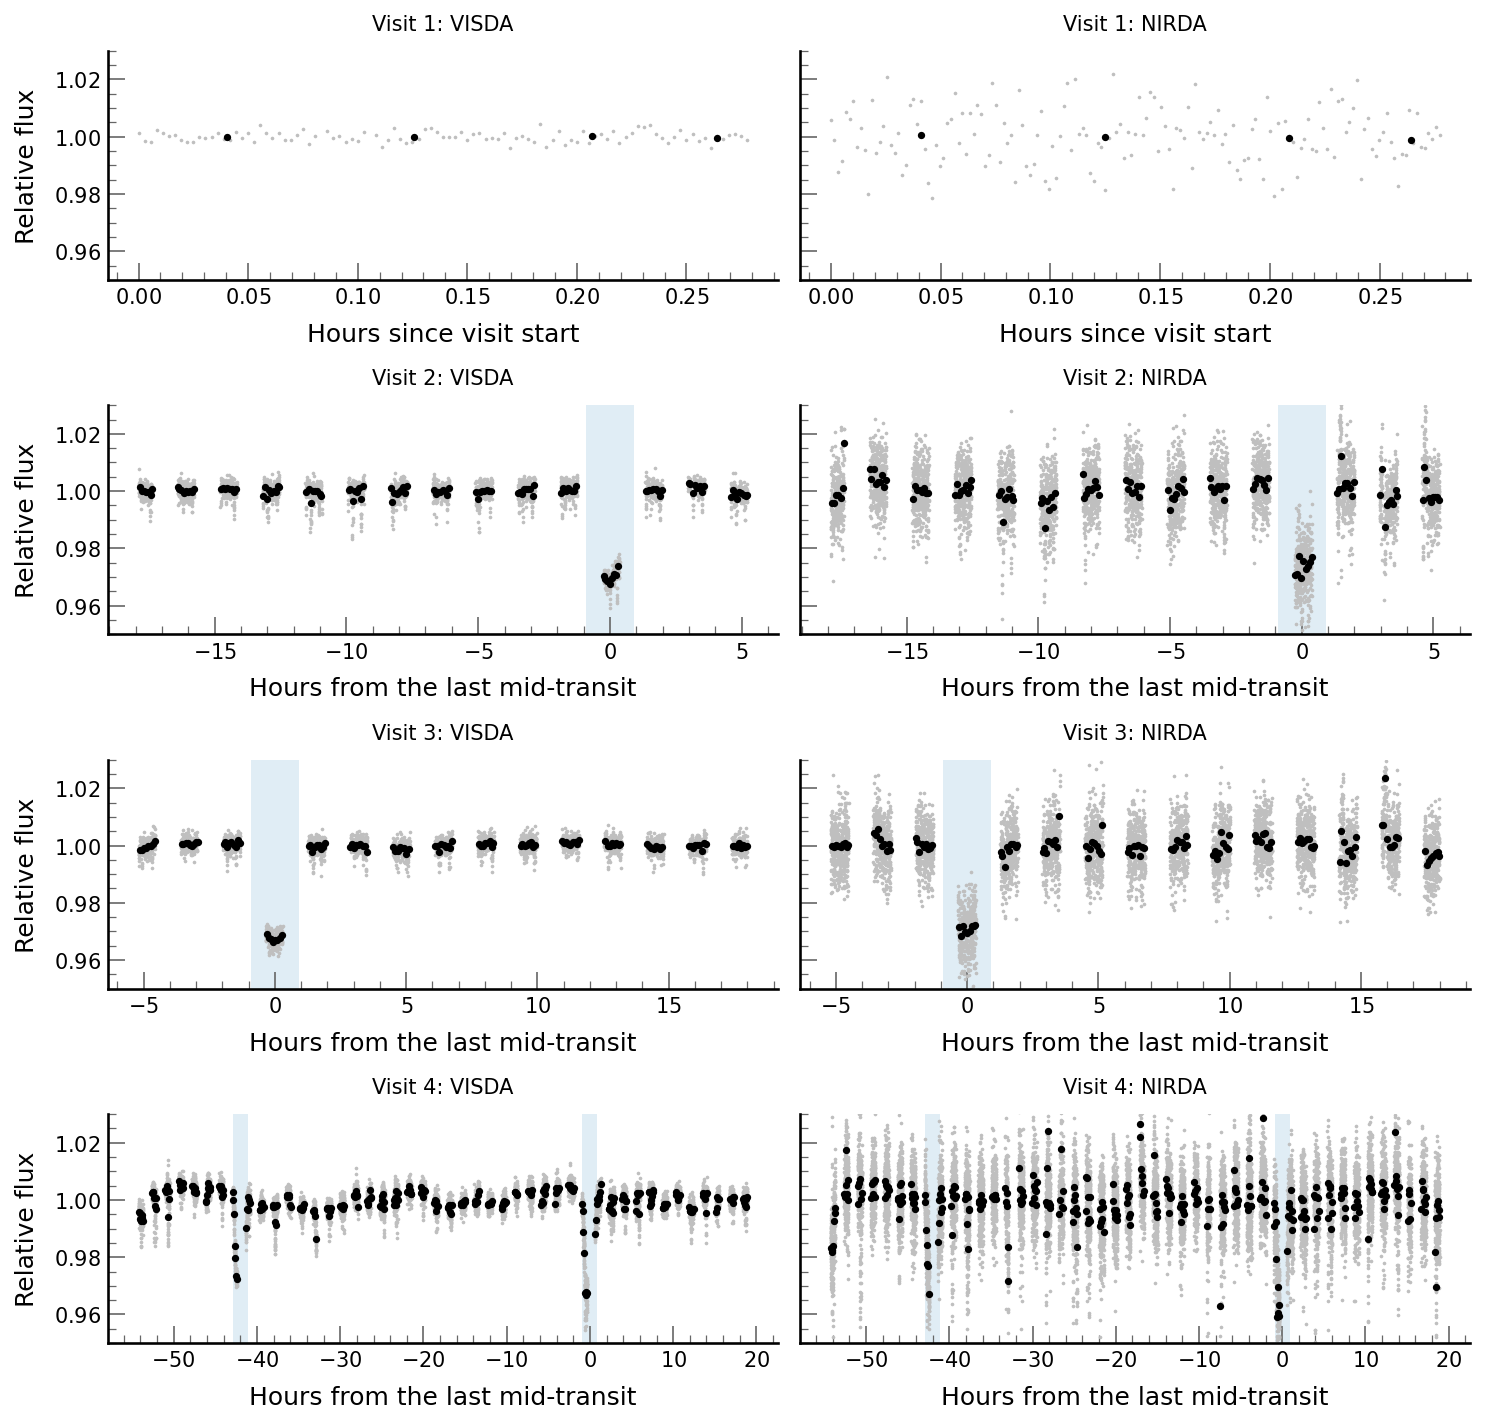

In [8]:
def visit_hours(part):
    # Hours from the last predicted mid-transit in the visit (else from the
    # visit start), and the hours of every predicted transit in the visit.
    mids = nearest_transit(part["bjd"].values)
    mids = np.unique(
        mids[(mids >= part["bjd"].min()) & (mids <= part["bjd"].max())]
    )
    reference = mids[-1] if mids.size else part["bjd"].min()
    return (
        (part["bjd"].values - reference) * 24,
        (mids - reference) * 24,
    )


def binned(x, y, width):
    edges = np.arange(x.min(), x.max() + width, width)
    which = np.digitize(x, edges)
    centers, means, errors = [], [], []
    for index in np.unique(which):
        in_bin = which == index
        if in_bin.sum() < 3:
            continue
        centers.append(x[in_bin].mean())
        means.append(y[in_bin].mean())
        errors.append(y[in_bin].std() / np.sqrt(in_bin.sum()))
    return np.array(centers), np.array(means), np.array(errors)


visits = sorted(visda["visit"].unique())
fig, axes = plt.subplots(len(visits), 2, figsize=(10, 2.4 * len(visits)),
                         sharey=True, squeeze=False)
for row_axes, visit in zip(axes, visits):
    for ax, table, name in zip(row_axes, (visda, nirda), ("VISDA", "NIRDA")):
        part = table.query("visit == @visit and keep")
        hours, transit_hours = visit_hours(part)
        ax.plot(hours, part["detrended"], ".", color="0.75", markersize=1.5)
        x, y, _ = binned(hours, part["detrended"].values, BIN_MINUTES / 60)
        ax.plot(x, y, ".", color="k", markersize=5)
        for mid in transit_hours:
            half = EPHEMERIS["duration_hours"] / 2
            ax.axvspan(mid - half, mid + half, color="#0072B2", alpha=0.12,
                       lw=0)
        ax.set_title(f"Visit {visit}: {name}", fontsize="medium")
        ax.set_xlabel("Hours from the last mid-transit" if transit_hours.size
                      else "Hours since visit start")
    row_axes[0].set_ylabel("Relative flux")
axes[0, 0].set_ylim(0.95, 1.03)
plt.show()

## Diagnostics

The background and the target's position over each visit, before flagging. Steps between files are normal (each file starts after a slew). A background that climbs at the end of a file is scattered earthshine; those frames are flagged above. Large position jumps are pointing problems, also flagged.

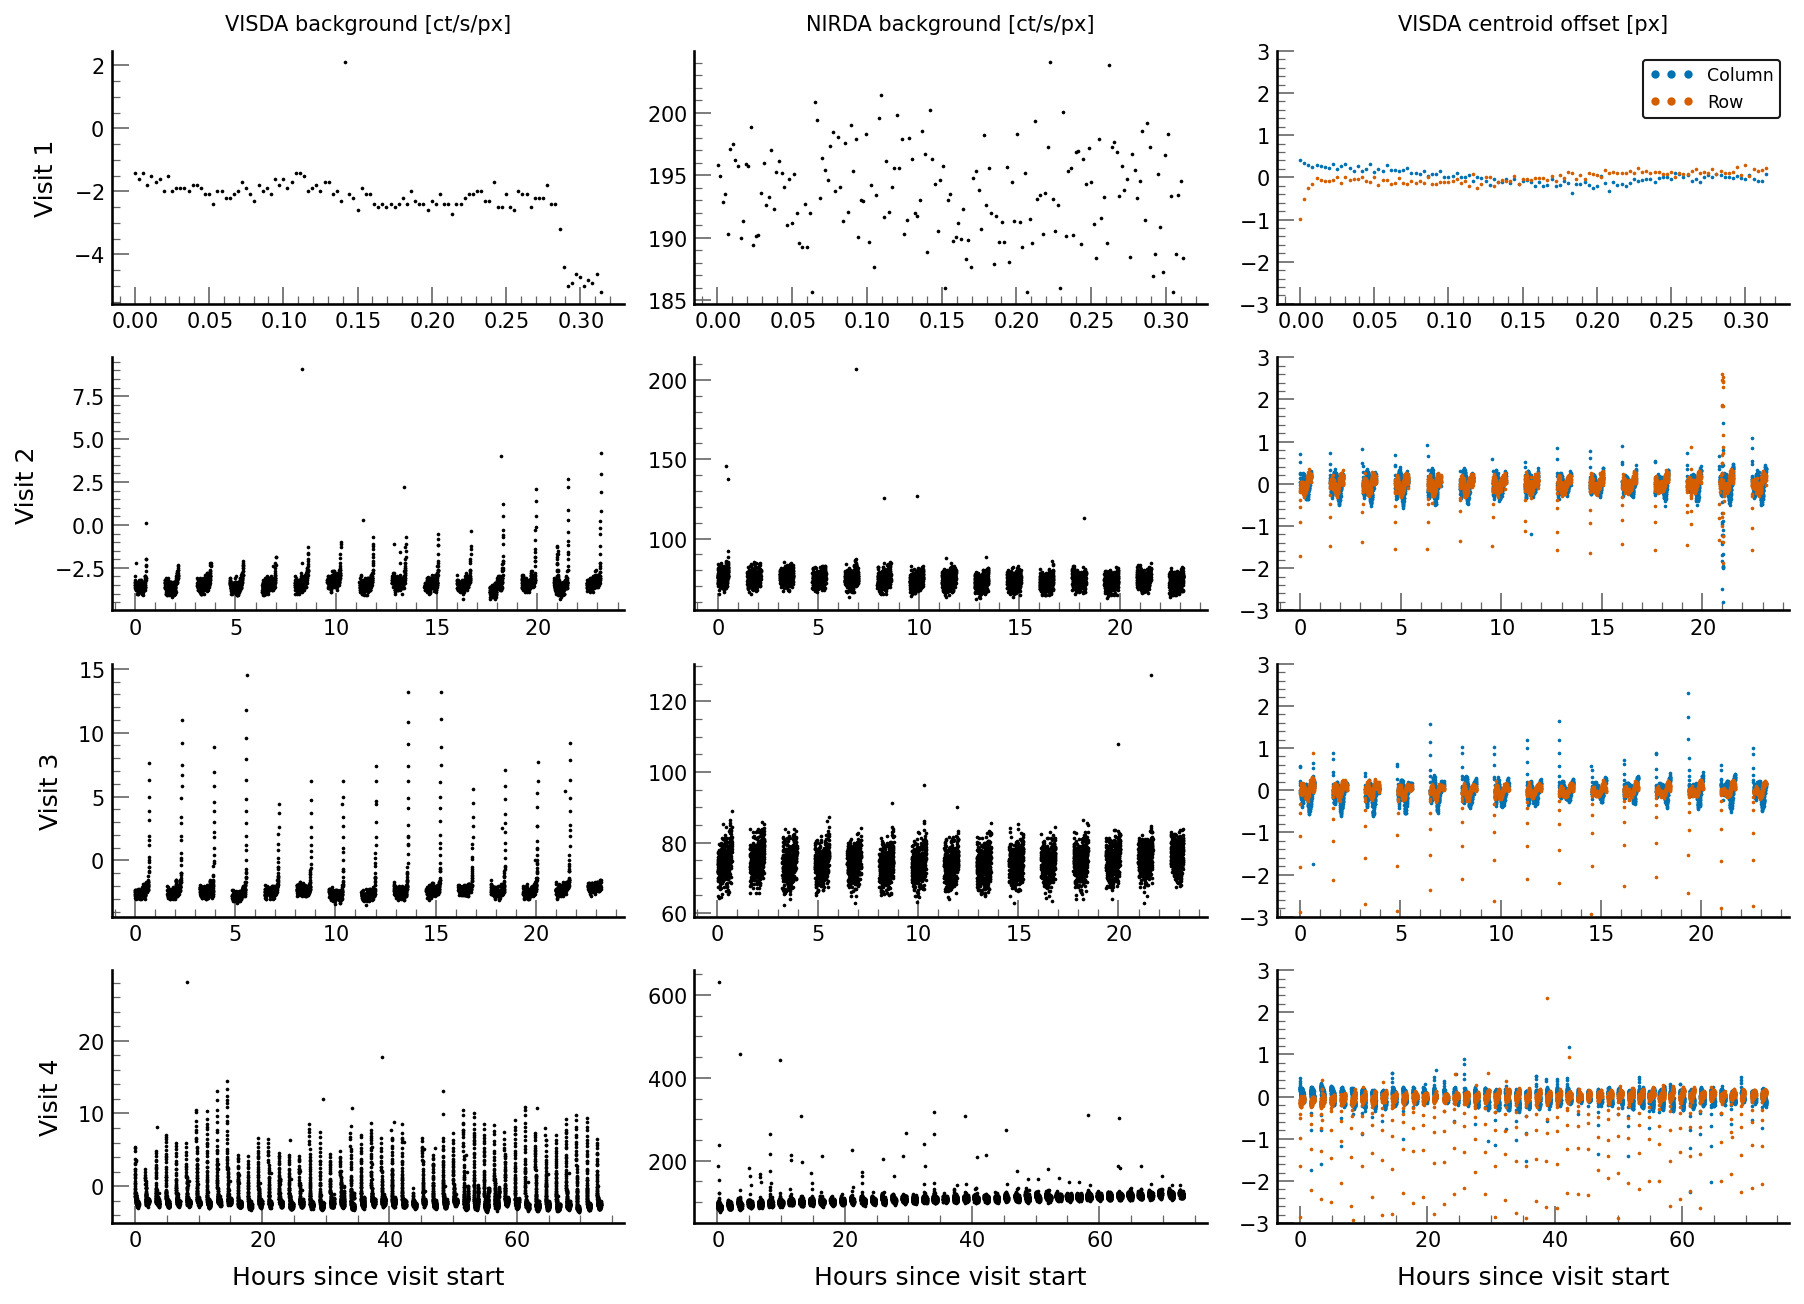

In [9]:
fig, axes = plt.subplots(len(visits), 3, figsize=(12, 2.2 * len(visits)),
                         squeeze=False)
for row_axes, visit in zip(axes, visits):
    vis = visda.query("visit == @visit")
    nir = nirda.query("visit == @visit")
    vis_hours = (vis["bjd"] - vis["bjd"].min()) * 24
    nir_hours = (nir["bjd"] - vis["bjd"].min()) * 24
    row_axes[0].plot(vis_hours, vis["background"], ".", color="k",
                     markersize=1.5)
    row_axes[1].plot(nir_hours, nir["background"], ".", color="k",
                     markersize=1.5)
    row_axes[2].plot(vis_hours, vis["column"] - vis["column"].median(), ".",
                     color="#0072B2", markersize=1.5, label="Column")
    row_axes[2].plot(vis_hours, vis["row"] - vis["row"].median(), ".",
                     color="#D55E00", markersize=1.5, label="Row")
    row_axes[0].set_ylabel(f"Visit {visit}")
    row_axes[2].set_ylim(-3, 3)
for ax, title in zip(axes[0], ["VISDA background [ct/s/px]",
                               "NIRDA background [ct/s/px]",
                               "VISDA centroid offset [px]"]):
    ax.set_title(title, fontsize="medium")
axes[0, 2].legend(loc="upper right", fontsize="small", markerscale=4)
for ax in axes[-1]:
    ax.set_xlabel("Hours since visit start")
plt.show()

## Transit

All visits folded on the predicted mid-transit times, for VISDA, the NIRDA white light curve and the NIRDA channels in `CHANNELS` (in order of wavelength). The *box depth* compares the mean flux in the middle half of the transit with the mean out of transit; it ignores limb darkening and the transit's shape, so it is a quick look rather than a measurement (a transit model fit is needed for that). The table gives the depth of each transit as well: a real spectral feature (helium, water) repeats from transit to transit, while instrumental problems usually affect one. The error used in the plot is the larger of the white-noise error and the error from the scatter between transits. Channels narrower than 5 rows are labeled with their width in rows.

Two things decide which transits a channel uses. Contaminated rows are left out of the channels (as from the white light curve), so a channel can be empty in visits where another star's trace covers it: for WASP-52, the 0.88-1.02 µm rows are contaminated in the September visits, which hold the two fully observed transits. And rows are weighted by their overlap with each channel, because each file's wavelength solution shifts the channel edges by a fraction of a row; counting whole rows instead would change a channel's flux from file to file by a full row (about 2% for a 0.2 µm channel, 50% for a 5 nm one).

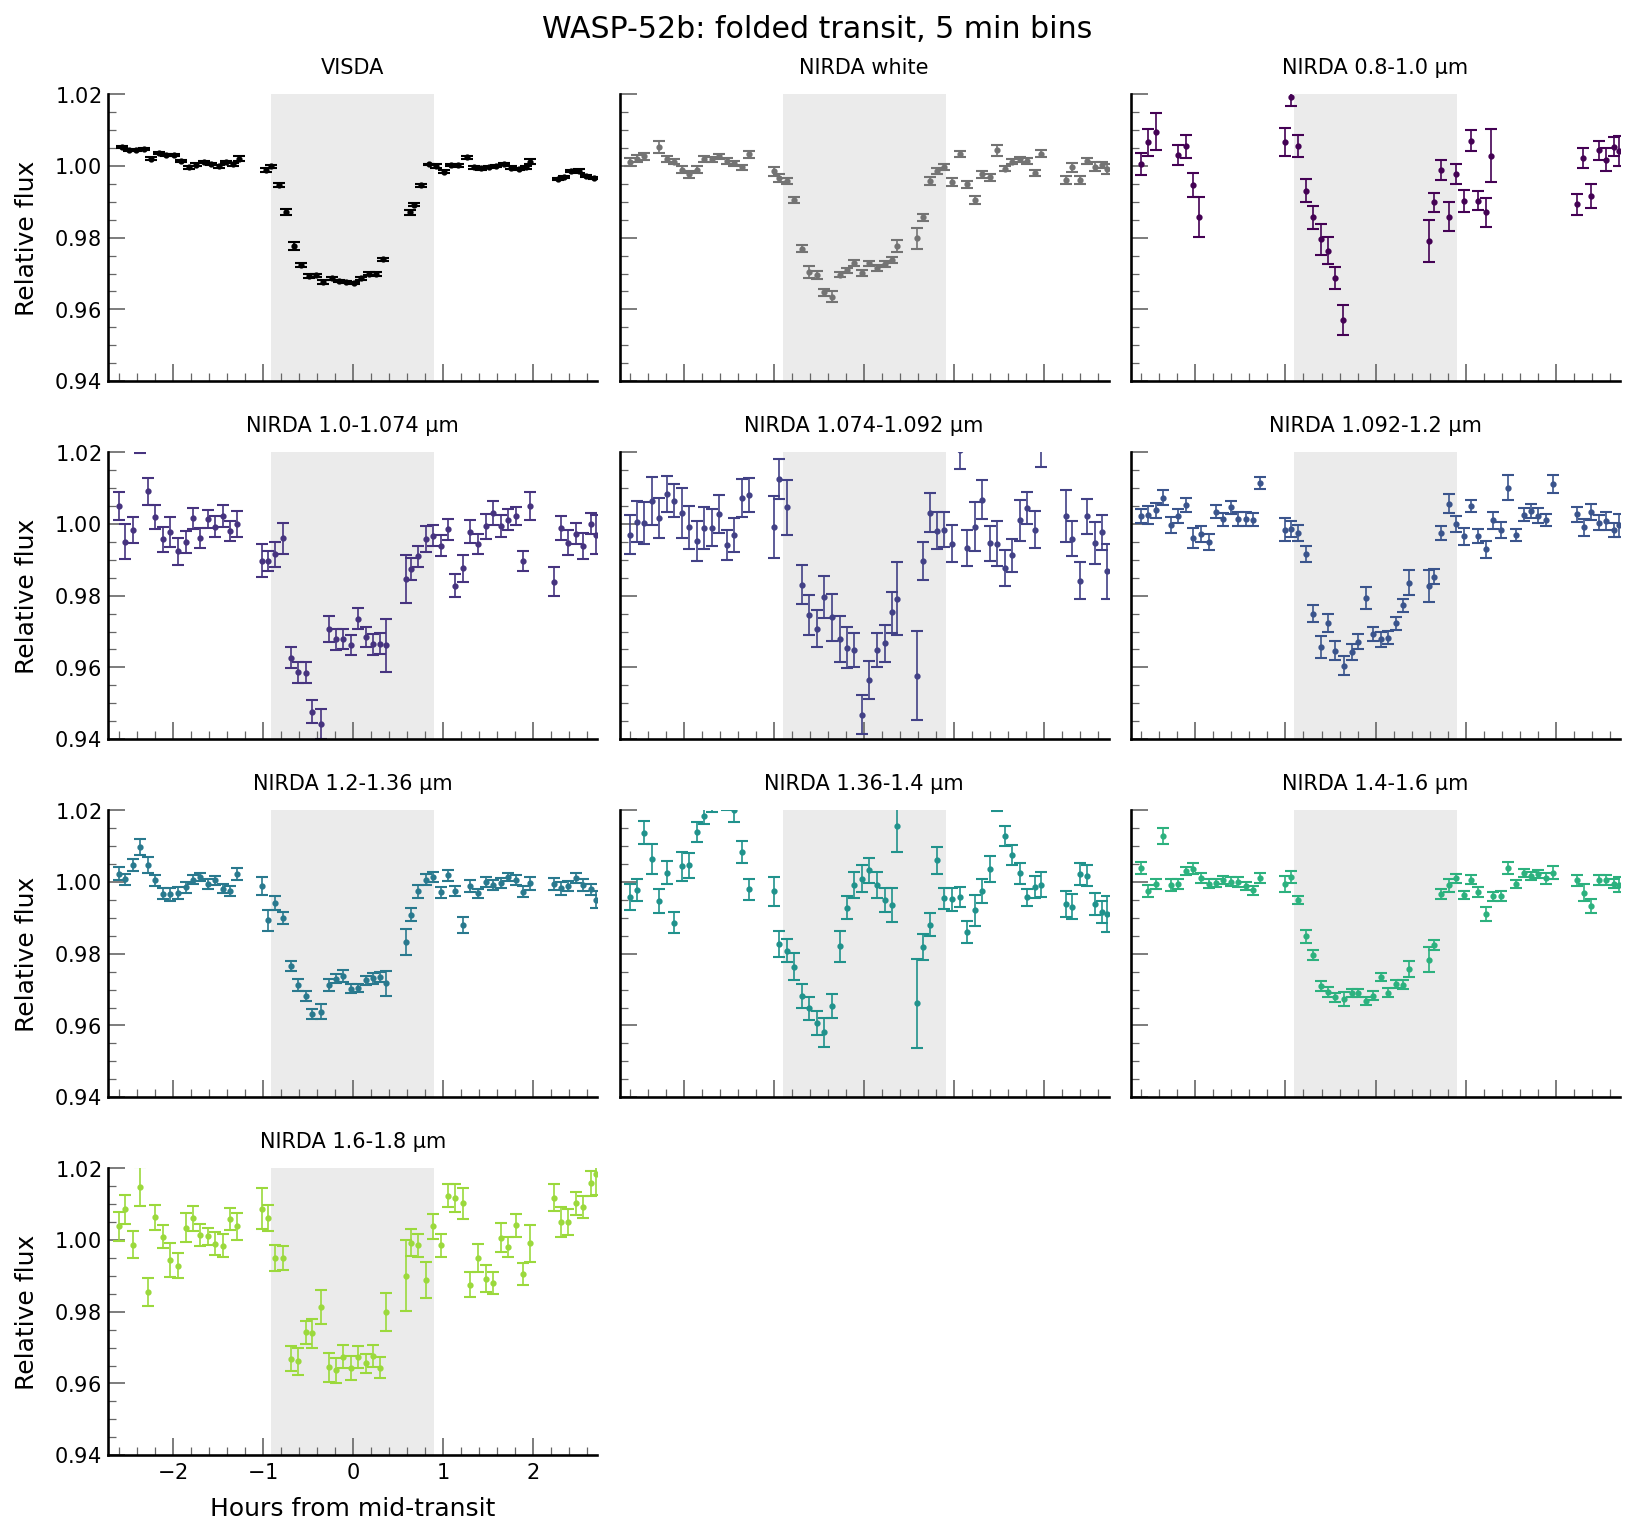

In [10]:
def folded(table, flux_column, keep_column):
    part = table[table[keep_column]]
    mids = nearest_transit(part["bjd"].values)
    return (part["bjd"].values - mids) * 24, part[flux_column].values, mids


def box_depth(hours, flux, mids):
    # Depth, its white-noise error and the number of transits with data in
    # the middle of the transit.
    duration = EPHEMERIS["duration_hours"]
    core = np.abs(hours) < duration / 4
    outside = np.abs(hours) > duration / 2 + TRANSIT_MARGIN_MINUTES / 60
    if core.sum() < 10:
        return np.nan, np.nan, 0
    baseline = flux[outside].mean()
    depth = 1 - flux[core].mean() / baseline
    error = np.hypot(flux[core].std() / np.sqrt(core.sum()),
                     flux[outside].std() / np.sqrt(outside.sum()))
    return depth, error, np.unique(mids[core]).size


def depth_summary(hours, flux, mids):
    # Box depth over all transits, its white-noise error, the depth of each
    # transit, and the error from the scatter between transits.
    depth, white_error, _ = box_depth(hours, flux, mids)
    each = []
    for mid in np.unique(mids):
        one = mids == mid
        if box_depth(hours[one], flux[one], mids[one])[2]:
            each.append(box_depth(hours[one], flux[one], mids[one])[0])
    scatter_error = (
        np.std(each, ddof=1) / np.sqrt(len(each)) if len(each) > 1
        else np.nan
    )
    # Transits counted are those with a depth of their own.
    return dict(depth=depth, white_error=white_error,
                scatter_error=scatter_error, transits=len(each),
                per_transit=each)


def short(value):
    # 0.800 -> "0.8", 1.000 -> "1.0", 1.085 -> "1.085"
    text = f"{value:.3f}".rstrip("0")
    return text + "0" if text.endswith(".") else text


# Channels in order of wavelength, colored by wavelength.
channels = sorted(CHANNELS, key=np.mean)
centers = np.array([np.mean(c) for c in channels])
shades = plt.cm.viridis(
    0.85 * (centers - centers.min()) / np.ptp(centers)
)
series = [("VISDA", visda, "detrended", "keep", "k"),
          ("NIRDA white", nirda, "detrended", "keep", "0.45")]
for (low, high), shade in zip(channels, shades):
    column = channel_name(low, high)
    series.append((f"NIRDA {short(low)}-{short(high)} µm", nirda,
                   column + "_detrended", column + "_keep", shade))
window = EPHEMERIS["duration_hours"] * 1.5 if EPHEMERIS else 0

if EPHEMERIS is not None:
    # One panel per light curve, all on the same scale.
    ncols = 3
    nrows = int(np.ceil(len(series) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(11, 2.6 * nrows),
                             sharex=True, sharey=True, squeeze=False)
    depths = []
    for ax, (label, table, flux_column, keep_column, color) in zip(
        axes.flat, series
    ):
        hours, flux, mids = folded(table, flux_column, keep_column)
        close = np.abs(hours) < window
        x, y, error = binned(hours[close], flux[close], BIN_MINUTES / 60)
        ax.axvspan(-EPHEMERIS["duration_hours"] / 2,
                   EPHEMERIS["duration_hours"] / 2, color="0.92", lw=0)
        ax.errorbar(x, y, error, fmt=".", color=color, markersize=4)
        ax.set_title(label, fontsize="medium")
        depths.append(dict(light_curve=label,
                           **depth_summary(hours, flux, mids)))
    for ax in axes.flat[len(series):]:
        ax.set_visible(False)
    for ax in axes[:, 0]:
        ax.set_ylabel("Relative flux")
    for ax in axes[-1]:
        ax.set_xlabel("Hours from mid-transit")
    axes[0, 0].set(xlim=(-window, window), ylim=(0.94, 1.02))
    fig.suptitle(f"{target_name}: folded transit, {BIN_MINUTES} min bins")
    plt.show()

                      box depth [ppm]  white-noise error  transit scatter error  transits  each transit [ppm]
light_curve                                                                                                  
VISDA                         31173.0              138.0                  827.0         3   29776 32431 32037
NIRDA white                   29071.0              308.0                 3678.0         3   26352 29441 38602
NIRDA 0.8-1.0 µm              37296.0             2967.0                    NaN         1               38483
NIRDA 1.0-1.074 µm            34383.0             1047.0                 9127.0         3   31094 32256 59039
NIRDA 1.074-1.092 µm          34881.0             1809.0                 5250.0         3   33811 38394 20860
NIRDA 1.092-1.2 µm            29906.0              738.0                 5141.0         3   24165 32982 41975
NIRDA 1.2-1.36 µm             29047.0              502.0                 4019.0         3   29301 26342 39603
NIRDA 1.36

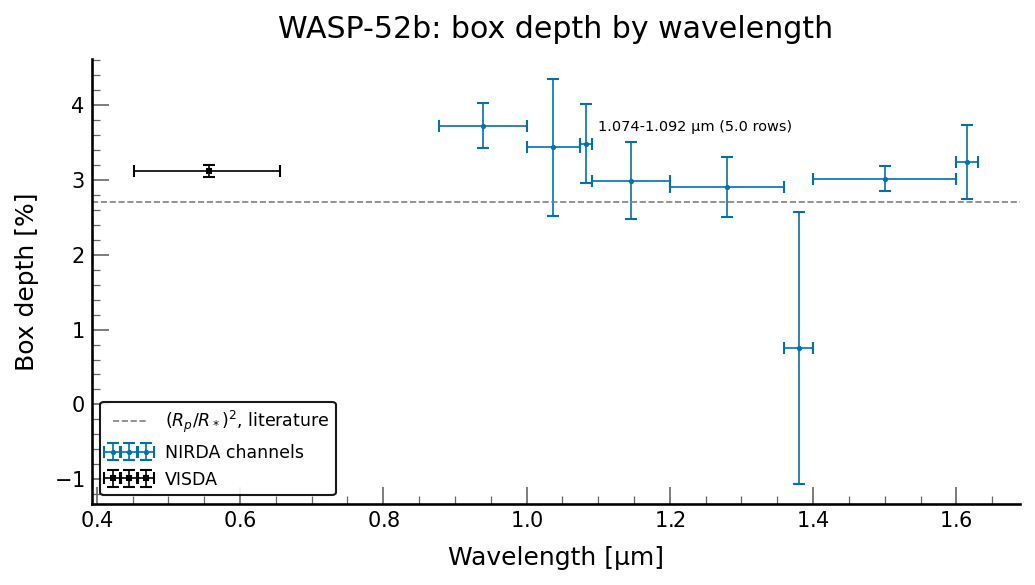

In [11]:
if EPHEMERIS is not None:
    # VISDA's effective wavelength and 16-84% range, from its sensitivity.
    grid = np.linspace(0.3, 1.1, 801) * u.micron
    weight = np.nan_to_num(
        pf.VISDAReference.get_sensitivity(grid).value
    )
    cumulative = np.cumsum(weight) / weight.sum()
    visda_wavelength = (grid.value * weight).sum() / weight.sum()
    visda_range = grid.value[np.searchsorted(cumulative, [0.16, 0.84])]

    depth_table = pd.DataFrame(depths).set_index("light_curve")
    # The error used is the larger of the white-noise error and the error
    # from the scatter between transits.
    depth_table["error"] = depth_table[
        ["white_error", "scatter_error"]
    ].max(axis=1)
    print(pd.DataFrame({
        "box depth [ppm]": (depth_table["depth"] * 1e6).round(),
        "white-noise error": (depth_table["white_error"] * 1e6).round(),
        "transit scatter error": (depth_table["scatter_error"] * 1e6).round(),
        "transits": depth_table["transits"],
        "each transit [ppm]": [
            " ".join(f"{d * 1e6:.0f}" for d in each)
            for each in depth_table["per_transit"]
        ],
    }).to_string())

    # Channels are drawn over the part of their range where NIRDA is
    # usable (in the first NIRDA file), since the outer channels extend past
    # it. Narrow channels are labeled with their width in detector rows.
    solution = pf.open(nirda_paths[0])["WAVELENGTH_SOLUTION"].data
    usable = solution["sensitivity"] > (
        MIN_RELATIVE_SENSITIVITY * np.nanmax(solution["sensitivity"])
    )
    usable_low = solution["wavelength"][usable].min()
    usable_high = solution["wavelength"][usable].max()
    row_width = np.median(np.abs(np.diff(solution["wavelength"][usable])))
    shown_low = np.array([max(low, usable_low) for low, _ in channels])
    shown_high = np.array([min(high, usable_high) for _, high in channels])
    shown_center = (shown_low + shown_high) / 2
    channel_depths = depth_table.iloc[2:]

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.errorbar(shown_center, channel_depths["depth"] * 100,
                yerr=channel_depths["error"] * 100,
                xerr=(shown_high - shown_low) / 2, fmt="o", color="#0072B2",
                label="NIRDA channels")
    for low, high, center, depth in zip(
        shown_low, shown_high, shown_center, channel_depths["depth"]
    ):
        rows = (high - low) / row_width
        if rows < 5 and np.isfinite(depth):
            ax.annotate(f"{short(low)}-{short(high)} µm ({rows:.1f} rows)",
                        (center, depth * 100), fontsize="x-small",
                        xytext=(6, 6), textcoords="offset points")
    ax.errorbar(visda_wavelength, depth_table.loc["VISDA", "depth"] * 100,
                yerr=depth_table.loc["VISDA", "error"] * 100,
                xerr=[[visda_wavelength - visda_range[0]],
                      [visda_range[1] - visda_wavelength]],
                fmt="s", color="k", label="VISDA")
    ax.axhline(RP_RS**2 * 100, color="0.5", ls="--",
               label=r"$(R_p/R_*)^2$, literature")
    ax.set(xlabel="Wavelength [µm]", ylabel="Box depth [%]",
           title=f"{target_name}: box depth by wavelength")
    ax.legend(loc="lower left", fontsize="small")
    plt.show()

## Caveats

- **Box depths are not transit depths.** Without limb darkening the middle of the transit is deeper than $(R_p/R_*)^2$ in the blue and less so in the red; fit a transit model (with the systematics above as regressors, rather than dividing them out first) for real measurements.
- **Narrow channels need more than this notebook.** A channel's flux changes by several percent per row that the trace moves along the dispersion, and by more near steep spectral structure. For WASP-52 the 1.36-1.40 µm channel gives a strongly negative depth in the first transit (2026-09-05) and normal depths in the others; neither a measured shift of the trace nor dividing by the white light curve removes it, which points to something local in those rows during that file (a hot or warm pixel, for example). Searching for helium or water features needs per-pixel inspection of the affected rows, channels referenced to their neighbors, and a transit model fit.
- **White-noise uncertainties are too small** when the noise is correlated (see the binning test in `01_visda_reduction.ipynb`); the transit-to-transit scatter is a more honest error.
- **Remaining outliers.** Some binned points still stand out (NIRDA in visit 4 of WASP-52, whose background also shows spikes). These simple flags miss episodes such as a warm detector; spacecraft telemetry (detector temperatures) makes better flags.
- **Level 2 caveats** from the 01 and 02 notebooks apply: the VISDA bias pattern (a per-file offset as the ROI moves), the NIRDA `BACKGROUND` (pandora-fits 0.9.0 and earlier include the subarray edge columns, which lowers NIRDA fluxes by up to a few percent and slightly increases relative depths), the NIRDA time stamps, and contamination flags from visible-light fluxes.